# 06 — Perbandingan Tiga Arsitektur CNN

Menggabungkan metrik test ResNet-50, MobileNetV3, dan InceptionV3 menjadi satu tabel perbandingan, lalu memilih model terbaik berdasarkan **F1 macro**.

Membaca `results/metrics/<model>_test_metrics.json`, jadi berfungsi baik untuk hasil dari CLI (`scripts.evaluate`) maupun dari notebook 03-05.

**Cara membaca yang jujur.** Dengan 5 kelas dan test set dari sejumlah foto terbatas, selisih F1 di bawah ~0.01 antar-arsitektur tidak cukup untuk menyimpulkan keunggulan. Lihat juga `defect_recall`: untuk quality control, biji cacat yang lolos jauh lebih mahal daripada salah menebak *jenis* cacatnya.

## Setup

In [25]:
# Bootstrap: tambahkan root proyek ke sys.path agar modul src/ & configs/ dapat diimpor.
import sys
from pathlib import Path

PROJECT_ROOT = Path.cwd().parent if Path.cwd().name == 'notebooks' else Path.cwd()
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

print('PROJECT_ROOT:', PROJECT_ROOT)

PROJECT_ROOT: c:\Users\DZXP\Documents\ta-green-bean


In [26]:
import json

import matplotlib.pyplot as plt
import pandas as pd

from configs.base_config import ANALYSIS_DIR, CLASS_NAMES, FIGURES_DIR, METRICS_DIR
from configs.cnn_config import CNN_CONFIG
from src.analysis.confusion_analysis import plot_confusion_matrices_comparison
from src.analysis.learning_curves import (
    convergence_summary,
    load_all_histories,
    plot_learning_curves,
)
from src.analysis.style import apply_plot_style, class_palette
from src.evaluation.predict import load_predictions

apply_plot_style()
METRIC_COLS = ['accuracy', 'precision', 'recall', 'f1']

## 1. Muat hasil evaluasi

In [27]:
reports = {}
for name in CNN_CONFIG:
    path = METRICS_DIR / f'{name}_test_metrics.json'
    if path.exists():
        reports[name] = json.loads(path.read_text(encoding='utf-8'))
    else:
        print(f'{name}: belum dievaluasi ({path.name} tidak ada)')

print('tersedia:', list(reports))

tersedia: ['resnet50', 'mobilenetv3', 'inceptionv3']


## 2. Tabel perbandingan utama

In [28]:
if not reports:
    df = pd.DataFrame()
    print('Jalankan evaluasi minimal satu model terlebih dahulu.')
else:
    df = pd.DataFrame(
        [
            {
                'model': name,
                **{k: r.get(k) for k in METRIC_COLS},
                'defect_recall': r.get('defect_recall'),
                'defect_miss_rate': r.get('defect_miss_rate'),
                'params': r.get('total_params'),
                'trainable': r.get('trainable_params'),
                'inference_ms': r.get('inference_ms'),
                'n_test': r.get('n_samples'),
            }
            for name, r in reports.items()
        ]
    ).set_index('model').sort_values('f1', ascending=False)

df

,accuracy,precision,recall,f1,defect_recall,defect_miss_rate,params,trainable,inference_ms,n_test
model,,,,,,,,,,
resnet50,0.835458,0.797524,0.794249,0.793337,0.906542,0.093458,23518277,10245,4.6064,863
mobilenetv3,0.811124,0.759599,0.752465,0.754205,0.899533,0.100467,4208437,6405,5.0068,863
inceptionv3,0.804171,0.755289,0.731995,0.742243,0.852804,0.147196,21795813,10245,9.7693,863


## 3. Bar chart metrik makro

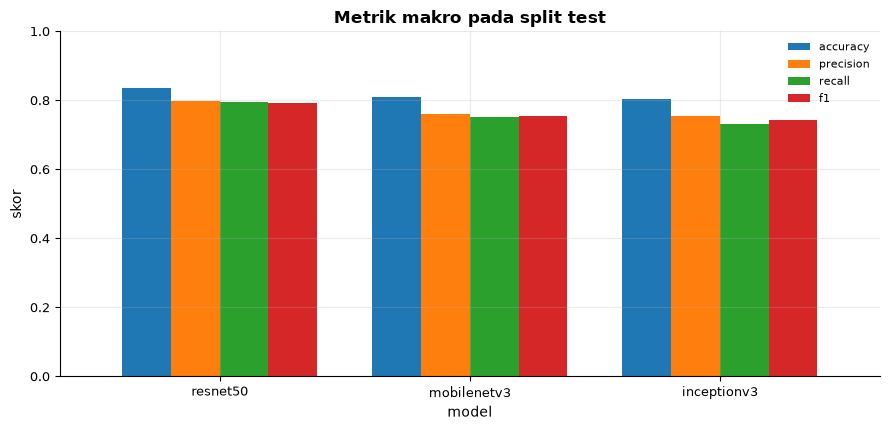

In [29]:
if not df.empty:
    ax = df[METRIC_COLS].plot(kind='bar', figsize=(9, 4.4), width=0.78)
    ax.set_ylim(0, 1.0)
    ax.set_ylabel('skor')
    ax.set_title('Metrik makro pada split test')
    ax.legend(fontsize=8)
    ax.tick_params(axis='x', rotation=0)
    plt.tight_layout()
    plt.show()

## 4. Metrik per kelas

Bagian paling informatif dari klasifikasi 5 kelas: rata-rata makro bisa menyembunyikan satu kelas cacat yang performanya buruk.

In [30]:
per_class_rows = []
for name, report in reports.items():
    for class_name, stats in report.get('per_class', {}).items():
        per_class_rows.append({'model': name, 'kelas': class_name, **stats})

df_per_class = pd.DataFrame(per_class_rows)
if not df_per_class.empty:
    display(df_per_class.pivot(index='kelas', columns='model', values='f1').reindex(CLASS_NAMES))
    display(df_per_class.pivot(index='kelas', columns='model', values='recall').reindex(CLASS_NAMES))

model,inceptionv3,mobilenetv3,resnet50
kelas,,,
good,0.892102,0.904926,0.905530
black,0.763780,0.751880,0.768683
chipped,0.644809,0.660287,0.733668
dry_pods,0.810526,0.853933,0.881720
insect_damage,0.600000,0.600000,0.677083


model,inceptionv3,mobilenetv3,resnet50
kelas,,,
good,0.921839,0.908046,0.903448
black,0.734848,0.757576,0.818182
chipped,0.614583,0.718750,0.760417
dry_pods,0.827957,0.817204,0.881720
insect_damage,0.560748,0.560748,0.607477


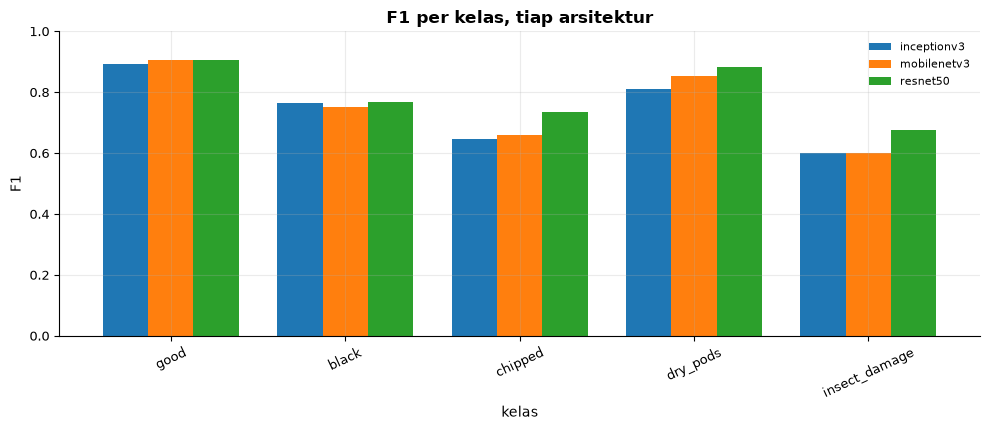

In [31]:
if not df_per_class.empty:
    pivot = df_per_class.pivot(index='kelas', columns='model', values='f1').reindex(CLASS_NAMES)
    ax = pivot.plot(kind='bar', figsize=(10, 4.4), width=0.78)
    ax.set_ylim(0, 1.0)
    ax.set_ylabel('F1')
    ax.set_title('F1 per kelas, tiap arsitektur')
    ax.tick_params(axis='x', rotation=25)
    ax.legend(fontsize=8)
    plt.tight_layout()
    plt.show()

## 5. Metrik quality control: layak vs cacat

`defect_miss_rate` = proporsi biji cacat yang lolos sebagai `good`. Ini angka yang paling relevan untuk operasional, dan paling mahal kalau tinggi.

,f1,defect_recall,defect_miss_rate
model,,,
resnet50,0.793337,0.906542,0.093458
mobilenetv3,0.754205,0.899533,0.100467
inceptionv3,0.742243,0.852804,0.147196


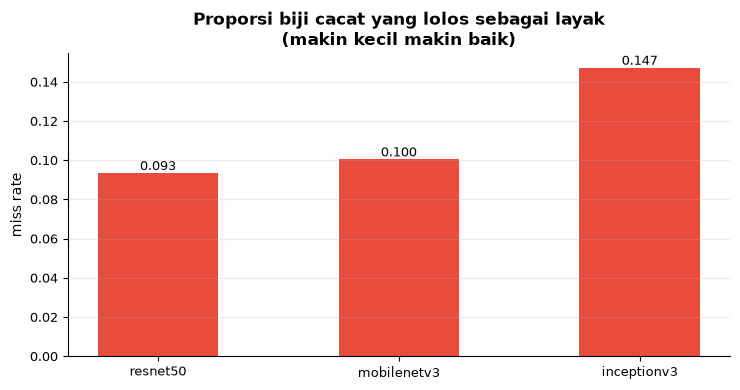

In [32]:
if not df.empty:
    qc = df[['f1', 'defect_recall', 'defect_miss_rate']].copy()
    display(qc)

    fig, ax = plt.subplots(figsize=(7.5, 4.0))
    ax.bar(qc.index, qc['defect_miss_rate'], color='#e74c3c', width=0.5)
    ax.set_ylabel('miss rate')
    ax.set_title('Proporsi biji cacat yang lolos sebagai layak\n(makin kecil makin baik)')
    for i, v in enumerate(qc['defect_miss_rate']):
        ax.text(i, v, f'{v:.3f}', ha='center', va='bottom', fontsize=9)
    plt.tight_layout()
    plt.show()

## 6. Confusion matrix ketiga model berdampingan

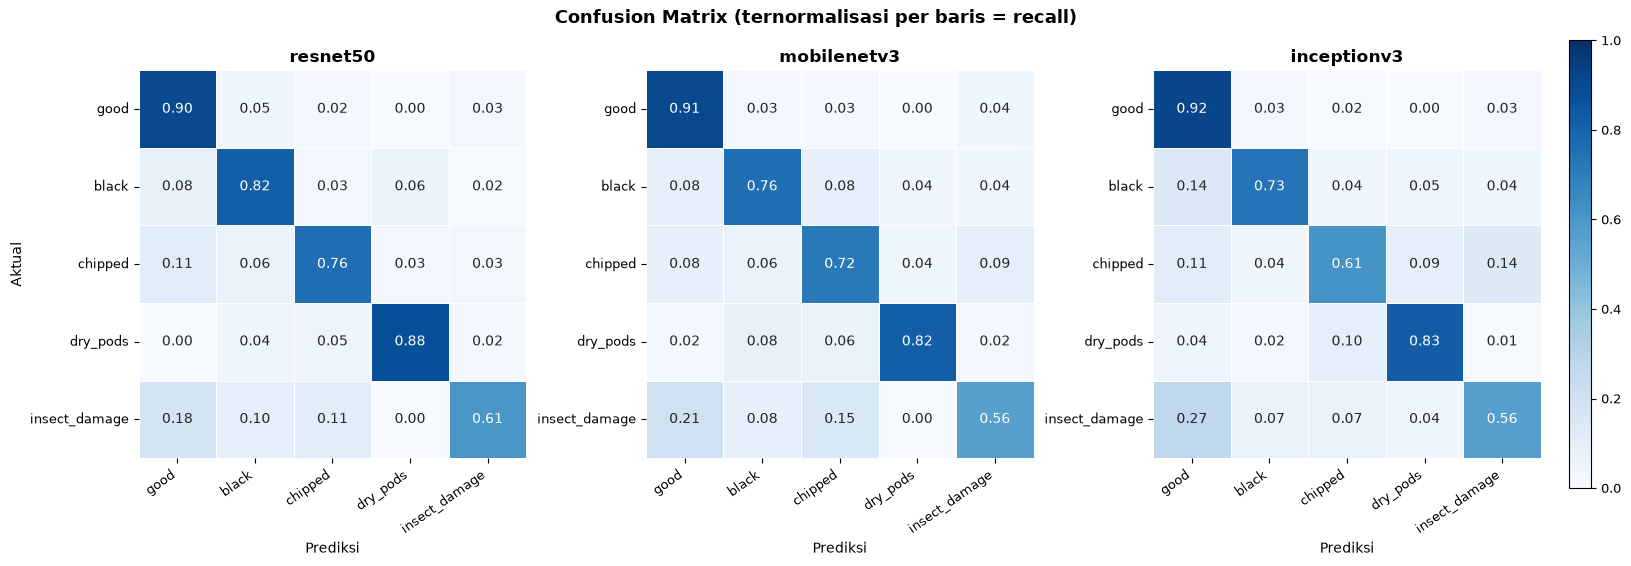

In [33]:
tables = {}
for name in reports:
    path = ANALYSIS_DIR / f'{name}_test_predictions.csv'
    if path.exists():
        tables[name] = load_predictions(path)

if tables:
    pairs = {n: (t['y_true'].tolist(), t['y_pred'].tolist()) for n, t in tables.items()}
    plot_confusion_matrices_comparison(
        pairs,
        class_names=CLASS_NAMES,
        normalize='true',
        output_path=FIGURES_DIR / 'confusion_matrices_comparison.png',
    )
else:
    print('Belum ada CSV prediksi. Jalankan scripts.evaluate untuk membuatnya.')

## 7. Kurva pembelajaran & konvergensi

,epochs_ran,best_epoch,best_val_acc,final_train_loss,final_val_loss,min_val_loss,overfitting_signal,generalization_gap,imbalance_strategy
model,,,,,,,,,
resnet50,30,12,0.8041,0.2668,0.5920,0.5442,0.0478,0.1248,class_weights
mobilenetv3,30,9,0.7810,0.4599,0.6896,0.6477,0.0420,0.0757,class_weights
inceptionv3,30,17,0.7555,0.8289,0.7510,0.6829,0.0681,-0.0492,class_weights


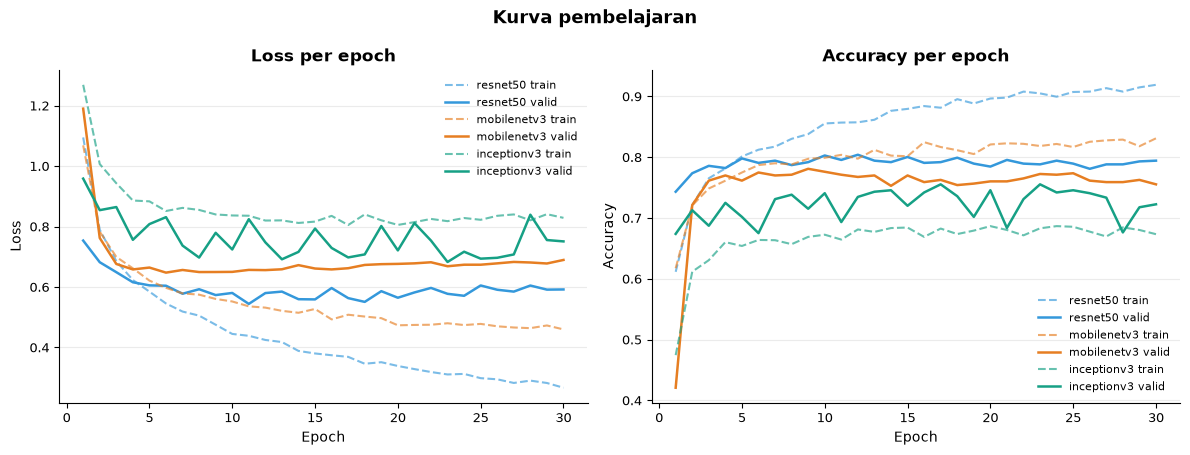

In [34]:
histories = load_all_histories(list(CNN_CONFIG))
if histories:
    plot_learning_curves(histories, output_path=FIGURES_DIR / 'learning_curves.png')
    display(convergence_summary(histories))
else:
    print('Belum ada history pelatihan.')

## 8. Trade-off akurasi vs efisiensi

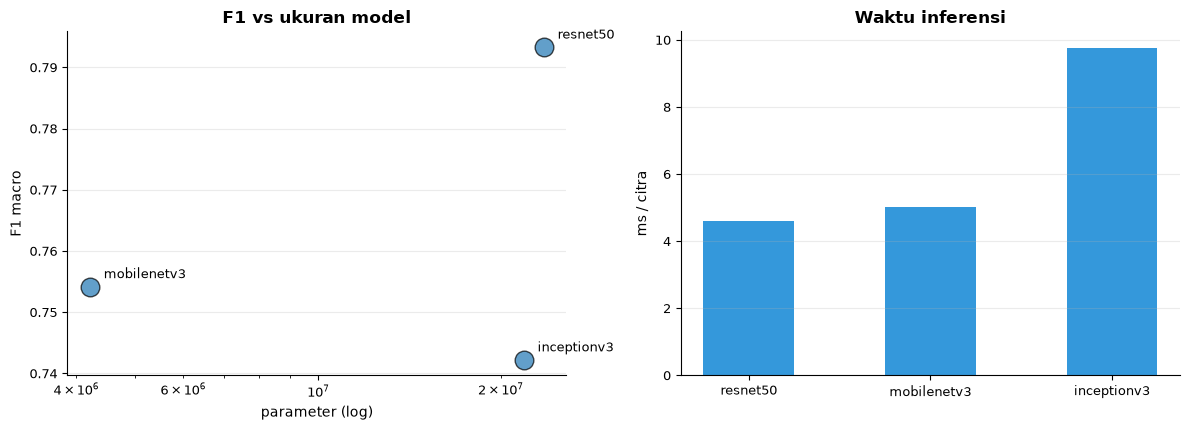

In [35]:
if not df.empty and df['inference_ms'].notna().any():
    fig, axes = plt.subplots(1, 2, figsize=(12, 4.4))

    axes[0].scatter(df['params'], df['f1'], s=180, alpha=0.7, edgecolors='black')
    for name, row in df.iterrows():
        axes[0].annotate(name, (row['params'], row['f1']),
                         textcoords='offset points', xytext=(10, 6), fontsize=9)
    axes[0].set_xscale('log')
    axes[0].set_xlabel('parameter (log)')
    axes[0].set_ylabel('F1 macro')
    axes[0].set_title('F1 vs ukuran model')

    axes[1].bar(df.index, df['inference_ms'], color='#3498db', width=0.5)
    axes[1].set_ylabel('ms / citra')
    axes[1].set_title('Waktu inferensi')

    fig.tight_layout()
    plt.show()

## 9. Pemilihan model terbaik

Kriteria utama **F1 macro**; kriteria pendamping `defect_recall` dan efisiensi.

In [36]:
if df.empty:
    print('Belum ada hasil untuk dianalisis.')
else:
    best = df.index[0]
    print(f'Terbaik menurut F1 macro : {best} ({df.loc[best, "f1"]:.4f})')

    if len(df) > 1:
        runner = df.index[1]
        gap = df.loc[best, 'f1'] - df.loc[runner, 'f1']
        print(f'Selisih dengan {runner}: {gap:.4f} F1')
        if gap < 0.01:
            print('  -> TERLALU TIPIS untuk menyimpulkan satu arsitektur lebih unggul.')
            print('     Laporkan sebagai setara, bukan sebagai kemenangan.')
        else:
            print('  -> selisihnya cukup untuk dibahas, dengan tetap menyebut')
            print('     keterbatasan jumlah foto sumber test set.')

    if 'defect_recall' in df.columns and df['defect_recall'].notna().any():
        qc_best = df['defect_recall'].idxmax()
        print()
        print(f'Terbaik untuk menangkap cacat: {qc_best} '
              f'(recall cacat {df.loc[qc_best, "defect_recall"]:.4f})')
        if qc_best != best:
            print('  -> berbeda dari pemenang F1; sebutkan keduanya di laporan.')

Terbaik menurut F1 macro : resnet50 (0.7933)
Selisih dengan mobilenetv3: 0.0391 F1
  -> selisihnya cukup untuk dibahas, dengan tetap menyebut
     keterbatasan jumlah foto sumber test set.

Terbaik untuk menangkap cacat: resnet50 (recall cacat 0.9065)


## 10. Langkah berikutnya

Analisis lanjutan ada di notebook berikut, atau sekali jalan lewat `python -m scripts.analyze`:

| Notebook | Isi |
| --- | --- |
| `07_gradcam_analysis.ipynb` | apa yang dilihat tiap arsitektur |
| `08_error_analysis.ipynb` | kelas apa tertukar, dan seperti apa bijinya |
| `09_feature_visualization.ipynb` | pemisahan kelas di ruang fitur |
| `10_efficiency_tradeoff.ipynb` | rekomendasi arsitektur per skenario deployment |